# Etapa 2 · Explicabilidad (SHAP) del modelo propuesto

Este cuaderno explica **qué variables usa LambdaMART para ordenar a los caballos** y lo usa como **control de calidad**: si una variable inesperada dominara, podría ser una fuga que se nos pasó.

**Qué es SHAP.** Para cada caballo, el modelo da un puntaje (mayor = más probable que gane). SHAP reparte ese puntaje entre las 22 variables: cada una recibe un *aporte* positivo (lo sube en el ranking) o negativo (lo baja), y la suma de los aportes da exactamente el puntaje. Se basa en los valores de Shapley de teoría de juegos. LightGBM los calcula de forma exacta para árboles con `pred_contrib=True`, así que no hace falta la librería `shap`.

**Requisito:** haber corrido el entrenamiento, que deja `results/models.joblib`:

```bash
python src/build_dataset.py --version v1
python scripts/run_experiments.py --data data/processed/dataset_v1.parquet --stage dev
```

Todo se calcula sobre validación (2004).

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

# Raíz del repo (sirve si el cuaderno se abre desde notebooks/ o desde la raíz)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results").is_dir())
RES = ROOT / "results"
FIG = RES / "figures"
FIG.mkdir(exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))
from hkr import data as D

val = D.split(D.load(ROOT / "data/processed/dataset_v1.parquet"), "val")
m = joblib.load(RES / "models.joblib")["lambdamart"]["model"]
print(f"Validación: {len(val):,} caballos en {val.race_id.nunique()} carreras")
print(f"LambdaMART: {m.model_.n_estimators} árboles, {len(m.features)} variables")

Validación: 9,902 caballos en 789 carreras
LambdaMART: 232 árboles, 22 variables


## 1. Valores SHAP

`pred_contrib=True` devuelve una columna por variable más una última columna con el valor base (el puntaje promedio). Se verifica que los aportes sumen el puntaje del modelo: si no sumaran, la explicación no correspondería al modelo.

In [2]:
X = m.enc_.transform(val[m.features])          # mismo preprocesamiento que en el entrenamiento
contrib = m.model_.predict(X, pred_contrib=True)
shap_vals = pd.DataFrame(contrib[:, :-1], columns=m.features)

score = m.model_.predict(X)
assert np.allclose(contrib.sum(axis=1), score), "los aportes no suman el puntaje"
print("Los aportes SHAP suman exactamente el puntaje del modelo para los", len(score), "caballos.")
shap_vals.head()

Los aportes SHAP suman exactamente el puntaje del modelo para los 9902 caballos.


,horse_age,horse_country,horse_type,horse_rating,declared_weight,actual_weight,draw,venue,config,surface,...,horse_ratings,prize,race_class,field_size,horse_win_rate,jockey_win_rate,trainer_win_rate,horse_days_since_last,horse_no_history,gear_any
0,-0.0082,-0.0173,-0.0006,-0.0355,-0.0658,0.0111,0.0795,-0.0105,-0.0104,0.0004,...,0.0686,-0.0002,0.0019,-0.0062,-0.1657,-0.3327,-0.1129,0.0503,0.0006,-0.0256
1,0.1042,0.0358,-0.0004,0.2338,0.0078,0.0300,-0.2033,-0.0053,0.0019,0.0007,...,0.0646,0.0284,0.0089,0.0018,-0.1470,-0.3421,0.0219,0.0369,0.0008,0.1250
2,-0.0084,-0.0205,-0.0003,-0.0371,0.0759,0.0706,0.1020,-0.0045,-0.0004,0.0003,...,0.0042,0.0089,0.0039,-0.0132,0.1896,-0.3046,0.0700,0.0379,0.0006,-0.0254
3,0.1117,-0.0242,-0.0008,0.3325,0.0715,0.1303,-0.1734,0.0217,0.0158,0.0000,...,0.0115,0.0156,0.0119,0.0071,0.0088,0.6373,0.0597,-0.0019,0.0008,0.1750
4,-0.0078,-0.0249,0.0001,-0.0387,-0.0376,0.0083,0.2196,-0.0030,0.0007,0.0003,...,0.0412,0.0041,0.0074,-0.0191,0.1192,0.1130,0.0329,0.0216,0.0006,-0.0228


## 2. Familias de variables

Las 22 variables se agrupan en cuatro familias. La importancia de una variable es el promedio del valor absoluto de su aporte (cuánto mueve el puntaje, sin importar la dirección), y la de una familia es la suma de las de sus variables.

In [3]:
FAMILIAS = {
    "Historial": ["horse_win_rate", "jockey_win_rate", "trainer_win_rate",
                  "horse_days_since_last", "horse_no_history"],
    "Caballo": ["horse_age", "horse_country", "horse_type", "horse_rating",
                "declared_weight", "actual_weight", "gear_any"],
    "Portón": ["draw"],
    "Carrera y pista": ["venue", "config", "surface", "distance", "going",
                        "horse_ratings", "prize", "race_class", "field_size"],
}
familia_de = {v: f for f, vs in FAMILIAS.items() for v in vs}
# Toda variable del modelo debe estar en exactamente una familia
assert sorted(familia_de) == sorted(m.features), set(m.features) ^ set(familia_de)

LambdaMART solo ordena caballos dentro de cada carrera: si una variable sube por igual el puntaje de todos los caballos de una carrera, no cambia quién queda primero. Por eso, además de la importancia global (la que pide la guía), se calcula la importancia **dentro de la carrera**: a cada aporte se le resta el promedio de su carrera, y queda solo la parte que distingue a un caballo de sus rivales.

In [4]:
codigos = D.race_codes(val)
shap_rel = shap_vals - shap_vals.groupby(codigos).transform("mean")   # aporte relativo a los rivales

imp = pd.DataFrame({
    "familia": pd.Series(familia_de),
    "global": shap_vals.abs().mean(),
    "dentro_carrera": shap_rel.abs().mean(),
})
imp["global_%"] = 100 * imp["global"] / imp["global"].sum()
imp["dentro_carrera_%"] = 100 * imp["dentro_carrera"] / imp["dentro_carrera"].sum()
imp = imp.sort_values("global", ascending=False)
imp.to_csv(RES / "shap_importance_lambdamart.csv", index_label="variable")
imp

,familia,global,dentro_carrera,global_%,dentro_carrera_%
jockey_win_rate,Historial,0.2718,0.2729,21.5012,26.2049
horse_rating,Caballo,0.1840,0.0781,14.5542,7.4979
horse_win_rate,Historial,0.1521,0.1302,12.0335,12.5027
draw,Portón,0.1330,0.1315,10.5234,12.6270
gear_any,Caballo,0.1041,0.0533,8.2331,5.1154
trainer_win_rate,Historial,0.0883,0.0824,6.9861,7.9099
horse_days_since_last,Historial,0.0654,0.0588,5.1726,5.6454
horse_age,Caballo,0.0586,0.0551,4.6365,5.2934
declared_weight,Caballo,0.0497,0.0473,3.9300,4.5444
actual_weight,Caballo,0.0347,0.0339,2.7415,3.2579


In [5]:
fam = imp.groupby("familia")[["global_%", "dentro_carrera_%"]].sum().sort_values("global_%", ascending=False)
fam

,global_%,dentro_carrera_%
familia,,
Historial,45.9216,52.4843
Caballo,36.0577,28.0729
Portón,10.5234,12.6270
Carrera y pista,7.4973,6.8158


## 3. Gráficos

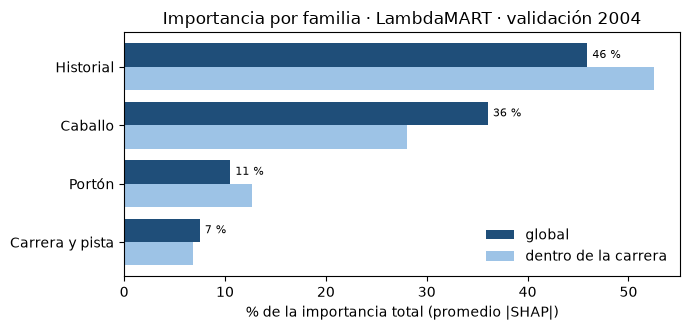

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.4))
y = np.arange(len(fam))
ax.barh(y - 0.2, fam["global_%"], height=0.4, color="#1f4e79", label="global")
ax.barh(y + 0.2, fam["dentro_carrera_%"], height=0.4, color="#9dc3e6", label="dentro de la carrera")
ax.set_yticks(y, fam.index)
ax.invert_yaxis()
ax.set_xlabel("% de la importancia total (promedio |SHAP|)")
ax.set_title("Importancia por familia · LambdaMART · validación 2004")
ax.legend(loc="lower right", frameon=False)
for i, v in enumerate(fam["global_%"]):
    ax.text(v + 0.5, i - 0.2, f"{v:.0f} %", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "shap_familias.png", dpi=150)
plt.show()

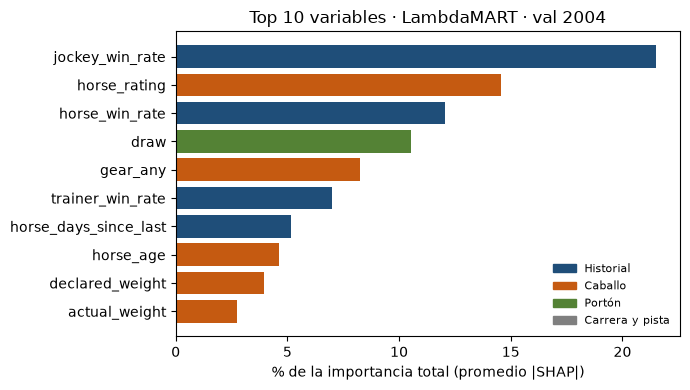

In [7]:
COLORES = {"Historial": "#1f4e79", "Caballo": "#c55a11", "Portón": "#548235", "Carrera y pista": "#7f7f7f"}
top = imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top.index, top["global_%"], color=[COLORES[f] for f in top["familia"]])
ax.set_xlabel("% de la importancia total (promedio |SHAP|)")
ax.set_title("Top 10 variables · LambdaMART · val 2004")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORES.values()]
ax.legend(handles, COLORES.keys(), loc="lower right", frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "shap_top10.png", dpi=150)
plt.show()

## 4. ¿En qué dirección empuja cada variable?

La importancia dice cuánto pesa una variable, no hacia dónde. Para las variables numéricas más importantes, se agrupan los caballos en quintiles del valor de la variable y se grafica el aporte SHAP promedio de cada grupo. Esto permite revisar si el efecto tiene sentido para alguien que sabe de carreras.

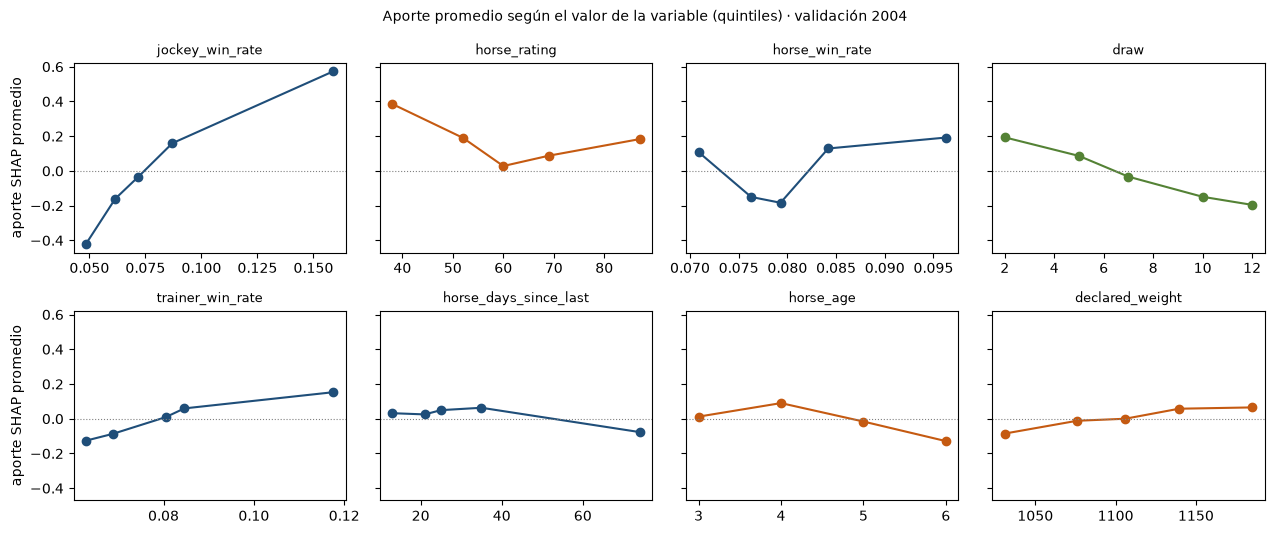

In [8]:
NUM = ["jockey_win_rate", "horse_rating", "horse_win_rate", "draw",
       "trainer_win_rate", "horse_days_since_last", "horse_age", "declared_weight"]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.4), sharey=True)
for ax, v in zip(axes.flat, NUM):
    x = val[v].astype(float)
    grupos = pd.qcut(x, 5, duplicates="drop")
    media = shap_vals[v].groupby(grupos.values, observed=True).mean()
    centro = x.groupby(grupos.values, observed=True).median()
    ax.plot(centro, media, "o-", color=COLORES[familia_de[v]])
    ax.axhline(0, color="grey", lw=0.8, ls=":")
    ax.set_title(v, fontsize=9)
axes[0, 0].set_ylabel("aporte SHAP promedio")
axes[1, 0].set_ylabel("aporte SHAP promedio")
fig.suptitle("Aporte promedio según el valor de la variable (quintiles) · validación 2004", fontsize=10)
plt.tight_layout()
plt.savefig(FIG / "shap_direccion.png", dpi=150)
plt.show()

`horse_win_rate` y `horse_rating` tienen una curva pronunciada o forma de U/V. La razón es que mezclan dos cosas: el nivel del caballo y la clase de la carrera (los caballos de tasa y rating bajos corren en carreras de clase baja, contra rivales igual de flojos). Para separarlas, se mide cada caballo contra los rivales de su carrera** (valor menos el promedio de la carrera) y se compara el aporte SHAP con la tasa de victoria real.

In [9]:
filas = {}
for v in ["horse_win_rate", "horse_rating"]:
    rel = val[v] - val[v].groupby(codigos).transform("mean")
    q = pd.qcut(rel, 5, labels=["Q1 (más bajo de su carrera)", "Q2", "Q3", "Q4", "Q5 (más alto)"])
    filas[(v, "SHAP promedio")] = shap_vals[v].groupby(q.values, observed=True).mean()
    filas[(v, "gana % real")] = 100 * val["won"].groupby(q.values, observed=True).mean()
pd.DataFrame(filas).T.round(2)

Q1 (más bajo de su carrera)      Q2      Q3  \
horse_win_rate SHAP promedio                       0.0000 -0.0500 -0.0700   
               gana % real                         6.8100  6.5700  7.2200   
horse_rating   SHAP promedio                       0.2500  0.1600  0.1700   
               gana % real                         6.9700  7.7500  8.9300   

                                 Q4  Q5 (más alto)  
horse_win_rate SHAP promedio 0.0400         0.1800  
               gana % real   8.5400        10.7500  
horse_rating   SHAP promedio 0.1700         0.1300  
               gana % real   7.8200         8.4400

In [10]:
# Las dos binarias: aporte promedio cuando valen 0 y cuando valen 1
for v in ["gear_any", "horse_no_history"]:
    print(v, shap_vals[v].groupby(val[v].values).mean().round(3).to_dict(),
          "· caballos:", val[v].value_counts().sort_index().to_dict())

gear_any {0: -0.025, 1: 0.129} · caballos: {0: 2337, 1: 7565}
horse_no_history {0: 0.002, 1: -0.027} · caballos: {0: 9478, 1: 424}


## 5. Control de calidad

Tres revisiones para descartar fugas o efectos raros.

**a) Variables de la carrera.** Las variables de "Carrera y pista" (premio, distancia, clase, tamaño del campo…) son iguales para todos los caballos de una carrera, así que por sí solas no pueden decir quién gana. Si alguna dominara como tal no sería algo esperado y habría que revisar a detalle.

In [11]:
fam.loc["Carrera y pista"]

global_%           7.4973
dentro_carrera_%   6.8158
Name: Carrera y pista, dtype: float64

b) `gear_any` sube el puntaje. Llevar equipo (anteojeras, lengüeta, etc.) empuja al caballo hacia arriba: es la 5.ª variable. Se revisa, año por año, cuántos caballos llevan equipo y cuánto ganan con y sin él.

In [12]:
full = D.load(ROOT / "data/processed/dataset_v1.parquet")
anual = (full.assign(año=full["date"].dt.year)
             .groupby(["año", "gear_any"])["won"].agg(["mean", "size"]).unstack("gear_any"))
gear_por_año = pd.DataFrame({
    "% con equipo": 100 * anual[("size", 1)].fillna(0) / anual["size"].sum(axis=1),
    "gana con equipo %": 100 * anual[("mean", 1)],
    "gana sin equipo %": 100 * anual[("mean", 0)],
    "split": full.groupby(full["date"].dt.year)["split"].first(),
}).round(1)
gear_por_año

,% con equipo,gana con equipo %,gana sin equipo %,split
1997,0.0000,0.0000,8.0000,train
1998,0.4000,12.9000,7.9000,train
1999,1.3000,11.5000,8.0000,train
2000,4.2000,12.6000,7.8000,train
2001,12.9000,10.9000,7.6000,train
2002,30.0000,11.5000,6.6000,train
2003,53.7000,9.9000,5.8000,train
2004,76.4000,8.1000,7.6000,val
2005,79.5000,8.1000,7.8000,test


**Qué muestra la tabla.** El registro de equipo pasa de 0 % en 1997 a casi 80 % en 2004–2005. En train, pocos caballos llevan equipo y esos ganan más (≈ 11 % contra ≈ 7 %), así que el modelo aprende "equipo = mejor". Pero en 2004 y 2005 casi todos llevan equipo y ganan igual que los que no (≈ 8 % ambos): **la relación que aprendió el modelo ya no se cumple**. No es una fuga (el equipo se declara antes de la carrera), sino un cambio en la distribución de los datos con el tiempo (*drift*), sea porque se popularizó el equipo o porque cambió la forma de registrarlo.

**Prueba rápida:** se reentrena LambdaMART con los mismos hiperparámetros, con y sin `gear_any`, con varias semillas, y se compara en validación. Solo usa train y validación; el modelo oficial de `results/` no cambia. Tarda unos segundos por semilla.

In [13]:
from hkr import metrics as M
from hkr.models import LambdaMART

tr = D.split(full, "train")
params = joblib.load(RES / "models.joblib")["lambdamart"]["params"]
sin_gear = [f for f in m.features if f != "gear_any"]
filas = []
for seed in [42, 1, 2, 3, 4]:
    s_con = LambdaMART(m.features, params, seed).fit(tr).score(val)
    s_sin = LambdaMART(sin_gear, params, seed).fit(tr).score(val)
    d = M.bootstrap_ci(val, s_sin, s_con)          # diferencia pareada en las mismas carreras
    filas.append({"semilla": seed,
                  "top-1 con gear %": 100 * M.top1_accuracy(val, s_con),
                  "top-1 sin gear %": 100 * M.top1_accuracy(val, s_sin),
                  "Δ top-1 (puntos)": 100 * d["top1_diff_vs_ref"],
                  "IC 95 % Δ": f"[{100 * d['top1_diff_lo']:+.1f}, {100 * d['top1_diff_hi']:+.1f}]",
                  "MRR con": M.mrr(val, s_con), "MRR sin": M.mrr(val, s_sin)})
abl = pd.DataFrame(filas).set_index("semilla")
display(abl.round(3))
print(f"Promedio: Δ top-1 = {abl['Δ top-1 (puntos)'].mean():+.2f} puntos, "
      f"Δ MRR = {(abl['MRR sin'] - abl['MRR con']).mean():+.4f}; "
      f"sin gear es mejor en {(abl['Δ top-1 (puntos)'] > 0).sum()} de {len(abl)} semillas")

,top-1 con gear %,top-1 sin gear %,Δ top-1 (puntos),IC 95 % Δ,MRR con,MRR sin
semilla,,,,,,
42,20.6590,21.0390,0.3800,"[-1.8, +2.5]",0.4110,0.4140
1,21.8000,22.6870,0.8870,"[-1.1, +2.9]",0.4150,0.4190
2,21.5460,21.1660,-0.3800,"[-2.5, +1.8]",0.4140,0.4110
3,22.3070,23.3210,1.0140,"[-0.9, +3.0]",0.4180,0.4250
4,21.0390,22.5600,1.5210,"[-0.5, +3.4]",0.4120,0.4170


Promedio: Δ top-1 = +0.68 puntos, Δ MRR = +0.0034; sin gear es mejor en 4 de 5 semillas


**c) `horse_rating` pierde peso dentro de la carrera.** Su importancia global es alta, pero baja a la mitad al medirla dentro de la carrera. En Hong Kong las carreras son *handicap*: los caballos de una carrera tienen ratings parecidos (por eso existe la banda `horse_ratings`) y el de mayor rating carga más peso. Se revisa cuánto gana, en la realidad, el caballo con el rating más alto de su carrera.

In [14]:
rk = val.groupby("race_id")["horse_rating"].rank(ascending=False, method="first")
print("Tasa de victoria en validación según la posición del caballo por rating dentro de su carrera:")
print(val.groupby(rk.values)["won"].mean().head(6).round(3).rename("tasa").to_frame().T)
print(f"\nTasa promedio (1/n): {(1 / val.groupby('race_id').size()).mean():.3f}")
print("Aporte SHAP promedio de horse_rating por clase de carrera:")
print(shap_vals["horse_rating"].groupby(val["race_class"].values).mean().round(2).to_frame("SHAP").T)

Tasa de victoria en validación según la posición del caballo por rating dentro de su carrera:
      1.0000  2.0000  3.0000  4.0000  5.0000  6.0000
tasa  0.0980  0.0810  0.0950  0.0720  0.0790  0.0720

Tasa promedio (1/n): 0.081
Aporte SHAP promedio de horse_rating por clase de carrera:
         0      1      2      3      4      5      6      11     12     13
SHAP 0.1600 0.2500 0.1300 0.0700 0.1700 0.4100 0.2100 0.3200 0.4300 0.2800


## 6. Hallazgos

> Los porcentajes se refieren a la importancia global salvo que se diga lo contrario; pueden variar unas décimas entre corridas en máquinas distintas.

1. **El historial domina, y el jinete es lo más importante.** La familia *Historial* concentra cerca de la mitad de la importancia, y `jockey_win_rate` es la variable número uno (≈ 21 % global, ≈ 26 % dentro de la carrera), con un efecto casi lineal: mejor tasa del jinete, mayor puntaje. Tiene sentido: en Hong Kong los mejores jinetes eligen montas y se suben a los mejores caballos, así que su tasa resume información del caballo y del entrenador. Es coherente con la comparación v0 vs. v1, donde agregar el historial fue lo que más mejoró a los modelos.

2. **Los efectos tienen la dirección que esperaría alguien que sabe de carreras.** Cajón bajo (`draw`, cerca del riel) ayuda; es la 4.ª variable y su efecto es casi una recta decreciente. Mucho tiempo sin correr (`horse_days_since_last`) y más edad (desde los 5 años) restan. Mayor tasa del entrenador suma. La tasa del caballo tiene forma de U en el gráfico global, pero es porque se mezcla con la clase de la carrera: comparada contra los rivales de su carrera, más tasa da más puntaje y el caballo gana más en la realidad (de ≈ 7 % a ≈ 11 %). Ninguna variable importante empuja en una dirección absurda.

3. **No hay señales de fuga.** Las variables de *Carrera y pista* suman poco (≈ 7.5 %) y ninguna está entre las primeras; `prize`, `race_class` y `field_size` están cerca de cero. Si el modelo estuviera usando información del resultado, lo esperable sería que una variable rara o de la carrera dominara, y no pasa. Esto complementa las pruebas automáticas contra fuga de `tests/`.

4. **`horse_rating` pesa menos de lo que parece.** Es la 2.ª variable global (≈ 15 %), pero dentro de la carrera baja a menos de la mitad (≈ 7.5 %), y su efecto no es monótono (tiene forma de U). En las carreras *handicap* los rivales tienen ratings parecidos y el de mayor rating carga más peso, así que el rating más alto de la carrera gana poco más que el promedio. El modelo usa el rating sobre todo para ubicar la **clase** de la carrera, no para elegir al ganador. Además, dentro de la carrera el modelo favorece un poco al de **menor** rating (que carga menos peso), mientras que en la realidad ese caballo gana algo menos: es un punto donde el modelo podría estar equivocándose. **Accionable:** para el ranking conviene reportar la importancia dentro de la carrera, y una variable "rating relativo a la carrera" podría ser más útil que el rating crudo.

5. **`gear_any` es la variable problemática: aprende una regla que dejó de cumplirse.** Es la 5.ª variable (≈ 8 %) y sube el puntaje de quien lleva equipo. Pero el registro de equipo pasa de 0 % de los caballos en 1997 a ≈ 80 % en 2004–2005, y la ventaja de llevarlo desaparece: en train los caballos con equipo ganan más, en validación ganan igual que los demás. No es una fuga, es un cambio de la distribución con el tiempo (*drift*), justo el tipo de problema en los datos que SHAP permite detectar. Al quitarla, LambdaMART mejora en promedio (sección 5b), aunque la diferencia cabe dentro del ruido. **Accionable:** quitar `gear_any` o reemplazarla por una variable estable (por ejemplo, "cambió de equipo respecto a su carrera anterior"); la decisión debe tomarse antes de evaluar test.

6. **Variables que casi no aportan.** `surface`, `horse_type`, `horse_no_history`, `going` y `race_class` suman menos de 1.5 % entre todas; son candidatas a quitarse en un estudio de ablación. `horse_no_history` sale casi en cero porque es redundante: un debutante ya se reconoce porque su `horse_win_rate` es exactamente el prior y `horse_days_since_last` está vacío.

**Nota sobre el ruido:** en la prueba de la sección 5b, el mismo LambdaMART da entre ≈ 20.7 % y ≈ 22.3 % de top-1 solo por cambiar la semilla. Diferencias de uno o dos puntos entre modelos deben leerse con los intervalos de confianza, no con el número suelto.

**Regla de ética:** los resultados se reportan por familia y por variable, nunca por jinete o entrenador individual.